# Accountant Validation

This notebook validates the `AdaptiveTCTAccountant` and `StandardDPAccountant` implementations before running the main experiments.

**Sections:**
1. Math primitives — Lemma 2.3 (q vs ε), α(i) schedule and prepaid compositions K_k
2. Per-user charging — how a single user's budget is consumed under each accountant
3. Telescoping invariant — empirical verification that total ε charged after k hits = K_{k+1}·ε
4. Simulation comparison — TCT vs IDP user retention and budget consumption

In [12]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import matplotlib.pyplot as plt

from simulation.population import User, UserPopulation
from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.calibration import q_from_epsilon, set_threshold_for_hit_rate
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.environment import SimulationEnvironment

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

## Section 1: Math Primitives

Verify the Lemma 2.3 relationship between q and ε, the dynamic alpha schedule (Theorem 3, Zeta-2 allocation), and prepaid composition count K_k.

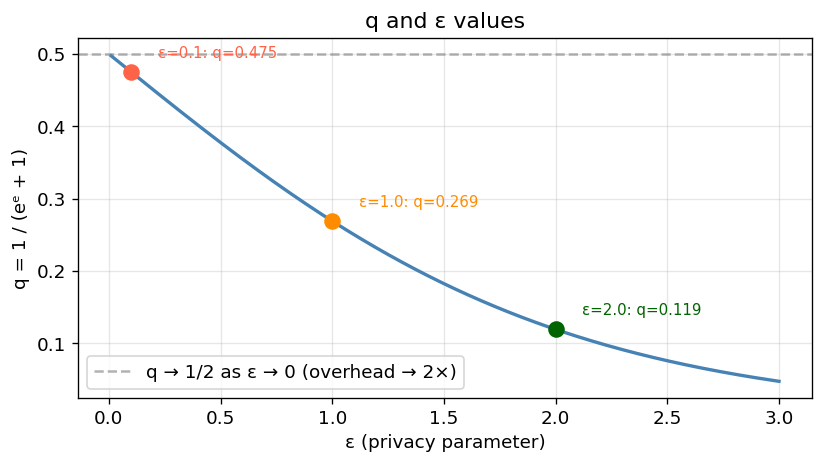

Lemma 2.3 values:
  ε=0.01:  q=0.4975  (composition overhead 1/q ≈ 2.01×)
  ε=0.10:  q=0.4750  (composition overhead 1/q ≈ 2.11×)
  ε=0.50:  q=0.3775  (composition overhead 1/q ≈ 2.65×)
  ε=1.00:  q=0.2689  (composition overhead 1/q ≈ 3.72×)
  ε=2.00:  q=0.1192  (composition overhead 1/q ≈ 8.39×)


In [13]:
# Lemma 2.3 (NotPrior target): q = 1/(e^ε + 1)
# q is a universal property of any ε-DP algorithm — independent of threshold T or data.
# It is NOT the empirical hit rate; the threshold T is set separately via set_threshold_for_hit_rate.

epsilon_range = np.linspace(0.01, 3.0, 300)
q_curve = [q_from_epsilon(e) for e in epsilon_range]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epsilon_range, q_curve, color='steelblue', linewidth=2)
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.6, label='q → 1/2 as ε → 0 (overhead → 2×)')

for eps, color in [(0.1, 'tomato'), (1.0, 'darkorange'), (2.0, 'darkgreen')]:
    q_val = q_from_epsilon(eps)
    ax.scatter([eps], [q_val], color=color, s=80, zorder=5)
    ax.annotate(f'ε={eps}: q={q_val:.3f}', xy=(eps, q_val),
                xytext=(eps + 0.12, q_val + 0.02), fontsize=9, color=color)

ax.set_xlabel('ε (privacy parameter)')
ax.set_ylabel('q = 1 / (eᵉ + 1)')
ax.set_title('q and ε values')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Lemma 2.3 values:')
for eps in [0.01, 0.1, 0.5, 1.0, 2.0]:
    q_val = q_from_epsilon(eps)
    print(f'  ε={eps:.2f}:  q={q_val:.4f}  (composition overhead 1/q ≈ {1/q_val:.2f}×)')

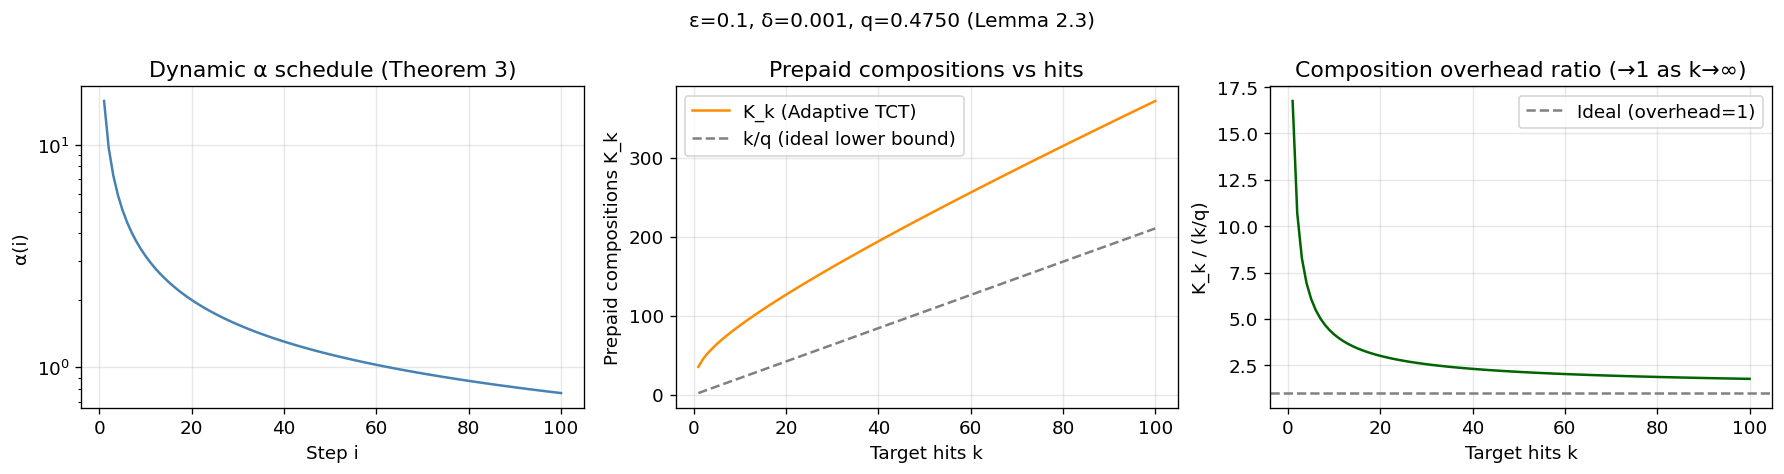

q = 1/(e^ε+1) = 0.4750  (ε=0.1, determined by Lemma 2.3)
K_1 (registration cost in compositions): 35.264
Registration ε cost (K_1·ε):             3.5264
Break-even with IDP (K_1 rounds):         35.3


In [14]:
# Parameters — q is derived from epsilon via Lemma 2.3, not set manually
EPSILON = 0.1
DELTA   = 1e-3

tct = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA)
q   = tct.q  # = 1/(e^epsilon + 1)

i_vals = np.arange(1, 101)
alpha_vals = [tct.alpha(i) for i in i_vals]
K_vals     = [tct.compositions(k) for k in i_vals]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(i_vals, alpha_vals, color='steelblue')
ax.set_xlabel('Step i')
ax.set_ylabel('α(i)')
ax.set_title('Dynamic α schedule (Theorem 3)')
ax.set_yscale('log')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(i_vals, K_vals, color='darkorange', label='K_k (Adaptive TCT)')
ax.plot(i_vals, i_vals / q, color='gray', linestyle='--', label='k/q (ideal lower bound)')
ax.set_xlabel('Target hits k')
ax.set_ylabel('Prepaid compositions K_k')
ax.set_title('Prepaid compositions vs hits')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[2]
overhead = [K_vals[i] / (i_vals[i] / q) for i in range(len(i_vals))]
ax.plot(i_vals, overhead, color='darkgreen')
ax.axhline(1.0, color='gray', linestyle='--', label='Ideal (overhead=1)')
ax.set_xlabel('Target hits k')
ax.set_ylabel('K_k / (k/q)')
ax.set_title('Composition overhead ratio (→1 as k→∞)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(f'ε={EPSILON}, δ={DELTA}, q={q:.4f} (Lemma 2.3)', fontsize=12)
plt.tight_layout()
plt.show()

print(f'q = 1/(e^ε+1) = {q:.4f}  (ε={EPSILON}, determined by Lemma 2.3)')
print(f'K_1 (registration cost in compositions): {tct.compositions(1):.3f}')
print(f'Registration ε cost (K_1·ε):             {tct.compositions(1)*EPSILON:.4f}')
print(f'Break-even with IDP (K_1 rounds):         {tct.compositions(1):.1f}')

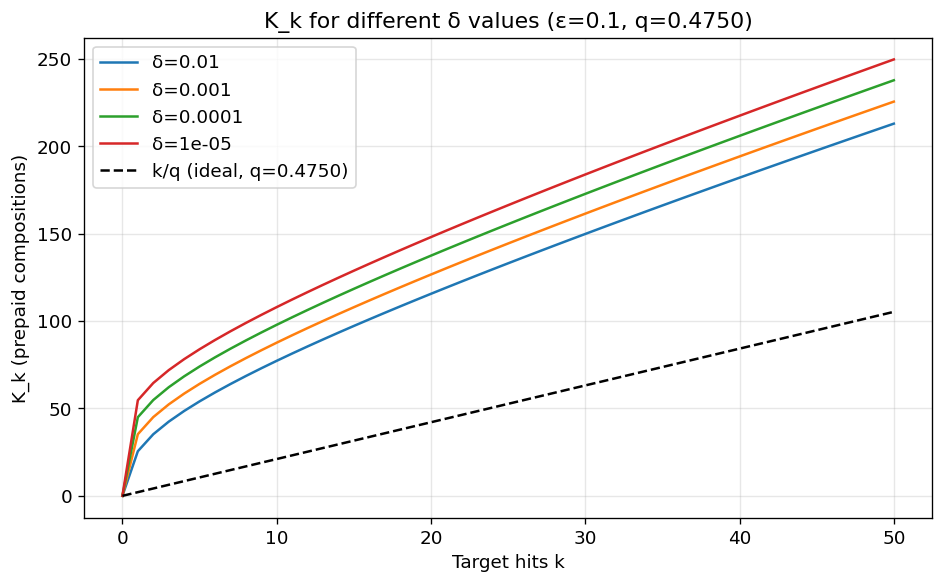

In [15]:
# Compare K_k across different delta values
# q is fixed by epsilon (Lemma 2.3) — same for all delta values
deltas = [1e-2, 1e-3, 1e-4, 1e-5]
k_vals_range = np.arange(0, 51)

fig, ax = plt.subplots(figsize=(8, 5))
for d in deltas:
    t = AdaptiveTCTAccountant(epsilon=EPSILON, delta=d)
    Ks = [t.compositions(k) for k in k_vals_range]
    ax.plot(k_vals_range, Ks, label=f'δ={d}')

ax.plot(k_vals_range, k_vals_range / q, 'k--', label=f'k/q (ideal, q={q:.4f})')
ax.set_xlabel('Target hits k')
ax.set_ylabel('K_k (prepaid compositions)')
ax.set_title(f'K_k for different δ values (ε={EPSILON}, q={q:.4f})')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Section 2: Per-User Charging Behavior

TCT's privacy advantage is **population-level, not per-user**.

For a user who contributes to every target hit, TCT is always slightly more expensive
than IDP (the α overhead), because the accountant pre-pays for uncertainty in the
number of private accesses needed. TCT wins at the population level because the majority
of users — those active in a round but not contributing to that round's hit — are charged
**nothing** under TCT after registration, while IDP charges them ε regardless.

This section compares two archetypes:
- **High contributor**: participates and contributes to every hit (worst case for TCT)
- **Non-contributor**: participates every round but never triggers a hit (best case for TCT)

**Key:** `q = 1/(e^ε + 1) ≈ 0.475` for ε=0.1 (Lemma 2.3 — determined by ε alone, not the data).
The empirical hit rate (1 hit every 5 rounds = 0.2) is set well below q, so 80% of rounds
are free under TCT after registration. The break-even with IDP is at round K₁ ≈ 16.

q (Lemma 2.3, ε=0.1): 0.4750  — determined by ε alone
Empirical hit rate:          1/5 = 0.20  (set below q)
K_1 = 15.7  →  registration cost = 1.572ε
Break-even with IDP = round 16
IDP depletes at round 145



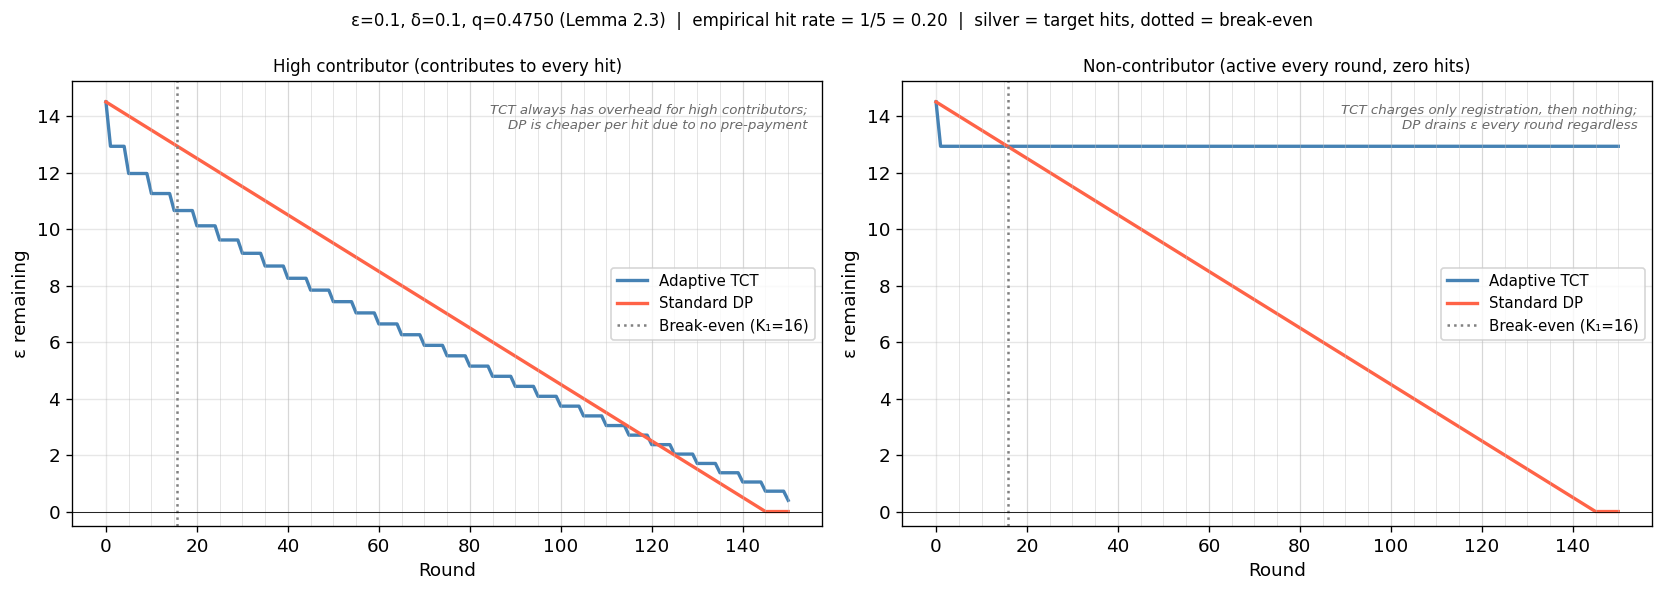

High contributor — TCT final ε: 0.40,  IDP final ε: 0.00
Non-contributor  — TCT final ε: 12.93,  IDP final ε: 0.00

→ IDP wins for high contributors (no registration overhead, no α pre-payment)
→ TCT wins for non-contributors (zero charge after registration vs ε/round under IDP)


In [16]:
EPSILON    = 0.1
DELTA      = 0.1     # moderate delta → small K_1, break-even visible early
EPS_BUDGET = 14.5    # IDP depletes ~round 145; TCT non-contributor survives all 150
N_ROUNDS   = 150
HIT_EVERY  = 5       # empirical hit rate = 0.2, well below q=0.475 for ε=0.1

tct_ref = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA)
K1 = tct_ref.compositions(1)
q  = tct_ref.q       # Lemma 2.3: 1/(e^0.1 + 1) ≈ 0.475

print(f'q (Lemma 2.3, ε={EPSILON}): {q:.4f}  — determined by ε alone')
print(f'Empirical hit rate:          1/{HIT_EVERY} = {1/HIT_EVERY:.2f}  (set below q)')
print(f'K_1 = {K1:.1f}  →  registration cost = {K1*EPSILON:.3f}ε')
print(f'Break-even with IDP = round {K1:.0f}')
print(f'IDP depletes at round {EPS_BUDGET/EPSILON:.0f}')
print()

def trace_user(contributed_to_hits: bool):
    tct = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA)
    idp = StandardDPAccountant(epsilon_per_round=EPSILON, delta_per_round=0.0)
    user_tct = User(user_id=0, epsilon_budget=EPS_BUDGET, delta_budget=1.0, conversion_rate=0.2)
    user_idp = User(user_id=1, epsilon_budget=EPS_BUDGET, delta_budget=1.0, conversion_rate=0.2)
    tct_rem, idp_rem = [EPS_BUDGET], [EPS_BUDGET]

    for r in range(1, N_ROUNDS + 1):
        is_top = (r % HIT_EVERY == 0)
        contributed = is_top and contributed_to_hits

        e, d = tct.charge(user_tct, is_top=is_top, contributed=contributed, round_num=r)
        user_tct.epsilon_spent += e; user_tct.delta_spent += d

        e, d = idp.charge(user_idp, is_top=is_top, contributed=contributed, round_num=r)
        user_idp.epsilon_spent += e; user_idp.delta_spent += d

        tct_rem.append(max(user_tct.epsilon_remaining, 0))
        idp_rem.append(max(user_idp.epsilon_remaining, 0))

    return tct_rem, idp_rem

tct_hi_rem, idp_hi_rem = trace_user(contributed_to_hits=True)
tct_lo_rem, idp_lo_rem = trace_user(contributed_to_hits=False)

rounds = range(N_ROUNDS + 1)
hit_rounds = [r for r in range(1, N_ROUNDS + 1) if r % HIT_EVERY == 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

panels = [
    (axes[0], tct_hi_rem, idp_hi_rem,
     'High contributor (contributes to every hit)',
     'TCT always has overhead for high contributors;\nDP is cheaper per hit due to no pre-payment'),
    (axes[1], tct_lo_rem, idp_lo_rem,
     'Non-contributor (active every round, zero hits)',
     'TCT charges only registration, then nothing;\nDP drains ε every round regardless'),
]

for ax, tct_rem, idp_rem, title, note in panels:
    ax.plot(rounds, tct_rem, color='steelblue', linewidth=2, label='Adaptive TCT')
    ax.plot(rounds, idp_rem, color='tomato',    linewidth=2, label='Standard DP')
    ax.axvline(K1, color='gray', linestyle=':', linewidth=1.5, label=f'Break-even (K₁={K1:.0f})')
    for h in hit_rounds:
        ax.axvline(h, color='silver', linewidth=0.6, alpha=0.4)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_xlabel('Round')
    ax.set_ylabel('ε remaining')
    ax.set_title(title, fontsize=10)
    ax.set_ylim(-0.5, EPS_BUDGET * 1.05)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.text(0.98, 0.95, note, transform=ax.transAxes, ha='right', va='top',
            fontsize=8, style='italic', color='dimgray')

plt.suptitle(
    f'ε={EPSILON}, δ={DELTA}, q={q:.4f} (Lemma 2.3)  |  '
    f'empirical hit rate = 1/{HIT_EVERY} = {1/HIT_EVERY:.2f}  |  '
    f'silver = target hits, dotted = break-even',
    fontsize=10
)
plt.tight_layout()
plt.show()

print(f'High contributor — TCT final ε: {tct_hi_rem[-1]:.2f},  IDP final ε: {idp_hi_rem[-1]:.2f}')
print(f'Non-contributor  — TCT final ε: {tct_lo_rem[-1]:.2f},  IDP final ε: {idp_lo_rem[-1]:.2f}')
print()
print('→ IDP wins for high contributors (no registration overhead, no α pre-payment)')
print('→ TCT wins for non-contributors (zero charge after registration vs ε/round under IDP)')

## Section 3: Telescoping Invariant

Theorem 5 requires that after k actual target hits, the IDP filter has charged exactly K_{k+1}·ε.
This section verifies that invariant empirically and plots the stepwise charge progression.

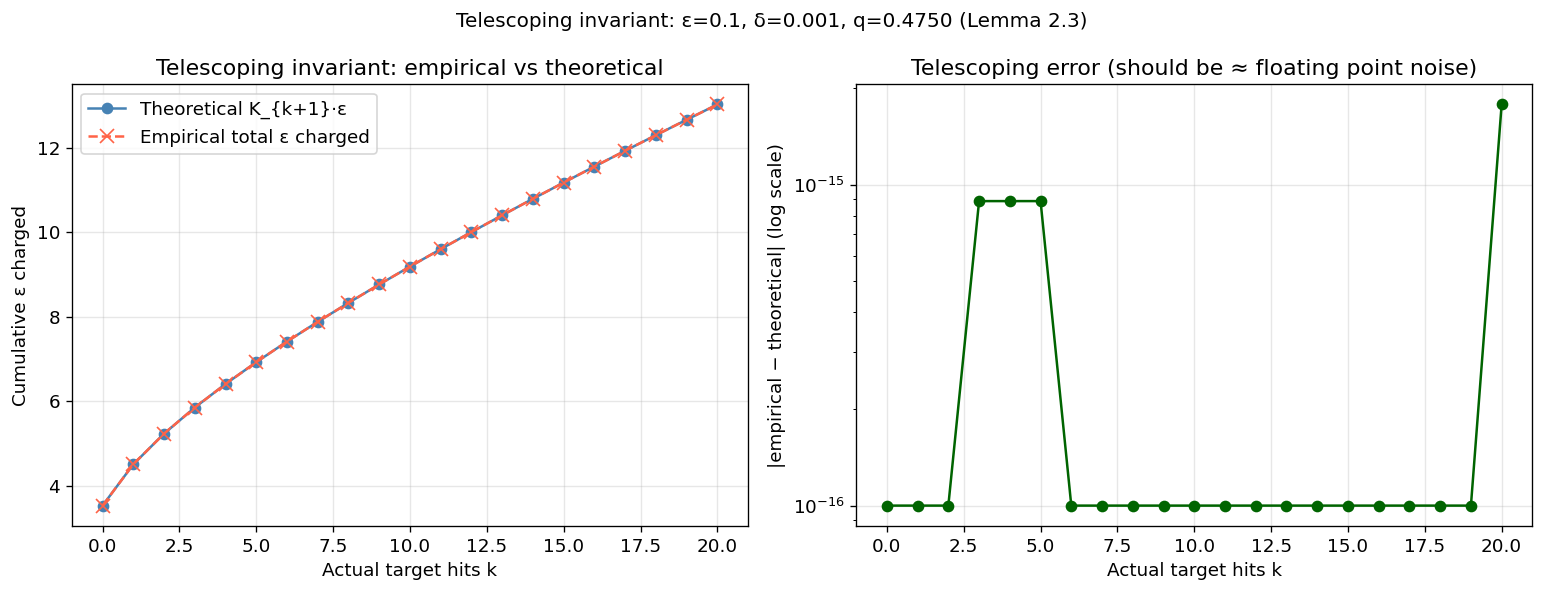

Max absolute error across k=0..20: 1.78e-15
PASS


In [17]:
EPSILON = 0.1
DELTA   = 1e-3
MAX_K   = 20

def simulate_k_hits(k, epsilon=EPSILON, delta=DELTA):
    """Simulate exactly k hits on a fresh accountant. Return total (eps, delta) charged."""
    tct  = AdaptiveTCTAccountant(epsilon=epsilon, delta=delta)
    user = User(user_id=0, epsilon_budget=1e9, delta_budget=1.0, conversion_rate=0.0)
    total_eps = 0.0
    total_delta = 0.0
    # Round 1: registration (not a hit)
    e, d = tct.charge(user, is_top=False, contributed=False, round_num=1)
    total_eps += e; total_delta += d
    # k hits
    for hit in range(1, k + 1):
        e, d = tct.charge(user, is_top=True, contributed=True, round_num=hit + 1)
        total_eps += e; total_delta += d
    return total_eps, total_delta

k_range = range(0, MAX_K + 1)
empirical_eps   = []
theoretical_eps = []
errors          = []

tct_ref = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA)

for k in k_range:
    emp_e, _ = simulate_k_hits(k)
    # After k hits, should equal K_{k+1} * epsilon (Theorem 5 telescoping invariant)
    theo_e = tct_ref.compositions(k + 1) * EPSILON
    empirical_eps.append(emp_e)
    theoretical_eps.append(theo_e)
    errors.append(abs(emp_e - theo_e))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(k_range, theoretical_eps, 'o-', color='steelblue', label='Theoretical K_{k+1}·ε')
ax.plot(k_range, empirical_eps,   'x--', color='tomato',    label='Empirical total ε charged', markersize=8)
ax.set_xlabel('Actual target hits k')
ax.set_ylabel('Cumulative ε charged')
ax.set_title('Telescoping invariant: empirical vs theoretical')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.semilogy(k_range, [max(e, 1e-16) for e in errors], 'o-', color='darkgreen')
ax.set_xlabel('Actual target hits k')
ax.set_ylabel('|empirical − theoretical| (log scale)')
ax.set_title('Telescoping error (should be ≈ floating point noise)')
ax.grid(True, alpha=0.3)

plt.suptitle(
    f'Telescoping invariant: ε={EPSILON}, δ={DELTA}, q={tct_ref.q:.4f} (Lemma 2.3)',
    fontsize=12
)
plt.tight_layout()
plt.show()

max_err = max(errors)
print(f'Max absolute error across k=0..{MAX_K}: {max_err:.2e}')
print('PASS' if max_err < 1e-10 else f'FAIL — max error {max_err:.2e} exceeds 1e-10')

## Section 4: Simulation Comparison

Run a full simulation with both accountants and compare:
- User retention (fraction of users with budget remaining)
- Average epsilon remaining over rounds

In [18]:
# Simulation parameters
N_USERS         = 500
N_ROUNDS        = 300
EPSILON         = 0.1
DELTA           = 1e-3
TARGET_HIT_RATE = 0.05   # empirical hit rate; must be << q for TCT to win
EPS_BUDGET      = 15.0
DELTA_BUDGET    = 1.0
SEED            = 42

# q is determined by epsilon alone (Lemma 2.3) — independent of T or data
q = q_from_epsilon(EPSILON)
print(f'q (Lemma 2.3, ε={EPSILON}):        {q:.4f}')
print(f'Target empirical hit rate:          {TARGET_HIT_RATE}  (≪ q — most rounds are free under TCT)')
print()

config = PopulationConfig(
    n_users=N_USERS, alpha=0.3, beta=0.7,
    epsilon_budget=EPS_BUDGET, delta_budget=DELTA_BUDGET
)
pop_tct = generate_synthetic_population(config, rng=np.random.default_rng(SEED))
pop_idp = generate_synthetic_population(config, rng=np.random.default_rng(SEED))

# Calibrate T so the noisy hit rate ≈ TARGET_HIT_RATE.
# T and q are independent: T is an application-level choice controlling how
# often the threshold is crossed; q = 1/(e^ε+1) is fixed by ε (Lemma 2.3).
calib_pop = generate_synthetic_population(config, rng=np.random.default_rng(SEED))
THRESHOLD, hit_rate_empirical = set_threshold_for_hit_rate(
    population=calib_pop,
    epsilon=EPSILON,
    target_hit_rate=TARGET_HIT_RATE,
    n_pilot=2000,
    rng=np.random.default_rng(999),
)

tct_ref = AdaptiveTCTAccountant(EPSILON, DELTA)
print(f'Threshold T (noisy (1-target) quantile):  {THRESHOLD:.2f}')
print(f'Pilot noisy hit rate:                     {hit_rate_empirical:.3f}  (target={TARGET_HIT_RATE})')
print()
print(f'K_1 (registration compositions):          {tct_ref.compositions(1):.1f}')
print(f'Registration ε cost (K_1·ε):              {tct_ref.compositions(1)*EPSILON:.3f}')
print(f'IDP depletion round (budget/ε):           {EPS_BUDGET/EPSILON:.0f}')

q (Lemma 2.3, ε=0.1):        0.4750
Target empirical hit rate:          0.05  (≪ q — most rounds are free under TCT)

Threshold T (noisy (1-target) quantile):  160.11
Pilot noisy hit rate:                     0.050  (target=0.05)

K_1 (registration compositions):          35.3
Registration ε cost (K_1·ε):              3.526
IDP depletion round (budget/ε):           150


In [19]:
# Run Adaptive TCT simulation
accountant_tct = AdaptiveTCTAccountant(epsilon=EPSILON, delta=DELTA)
env_tct = SimulationEnvironment(
    population=pop_tct,
    accountant=accountant_tct,
    threshold=THRESHOLD,
    query_epsilon=EPSILON,
    num_rounds=N_ROUNDS,
    rng=np.random.default_rng(SEED),
)
result_tct = env_tct.run()

# Run Standard IDP simulation
accountant_idp = StandardDPAccountant(epsilon_per_round=EPSILON, delta_per_round=0.0)
env_idp = SimulationEnvironment(
    population=pop_idp,
    accountant=accountant_idp,
    threshold=THRESHOLD,
    query_epsilon=EPSILON,
    num_rounds=N_ROUNDS,
    rng=np.random.default_rng(SEED),
)
result_idp = env_idp.run()

print(f'TCT: {len(result_tct.rounds)} rounds completed, {result_tct.total_queries_answered} queries answered')
print(f'IDP: {len(result_idp.rounds)} rounds completed, {result_idp.total_queries_answered} queries answered')

TCT: 300 rounds completed, 300 queries answered
IDP: 151 rounds completed, 151 queries answered


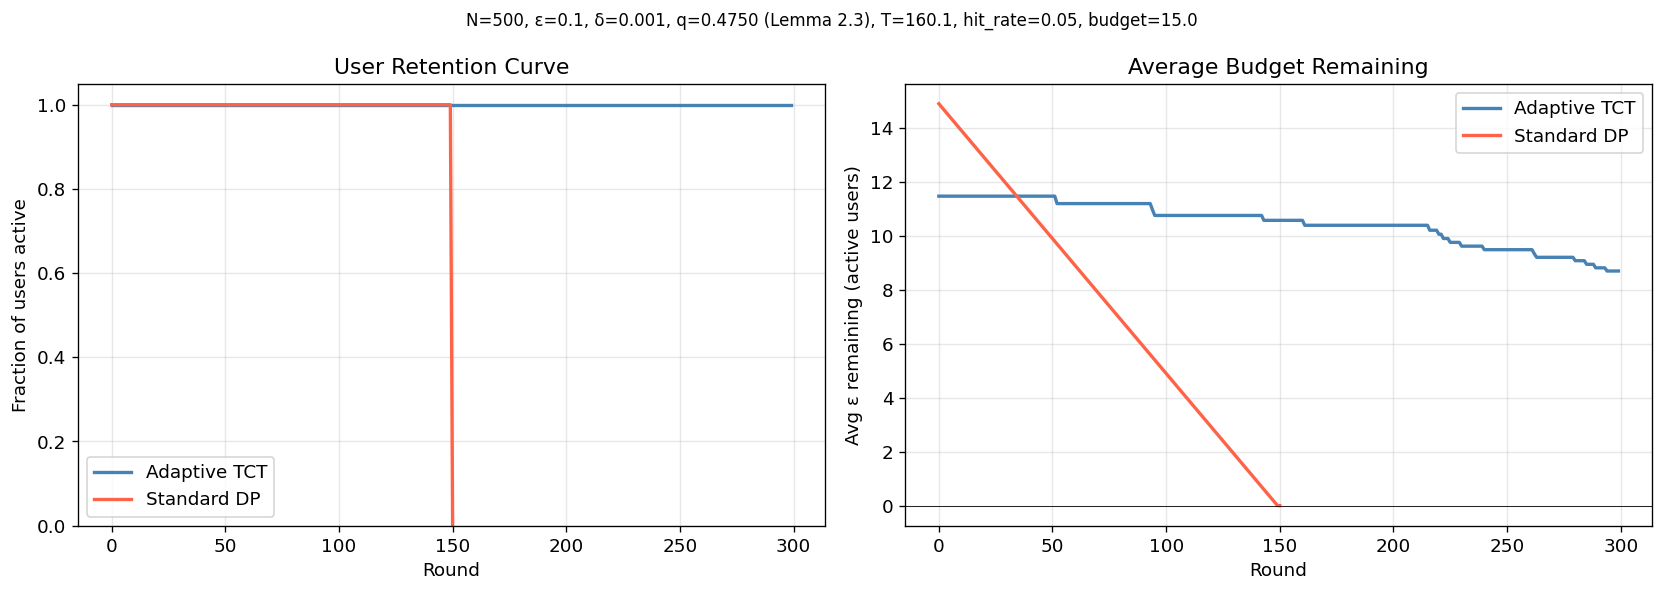

TCT final active fraction: 1.000
IDP final active fraction: 0.000
TCT final avg ε remaining: 8.6982
IDP final avg ε remaining: 0.0000


In [20]:
tct_active   = result_tct.active_fraction_by_round()
idp_active   = result_idp.active_fraction_by_round()
tct_avg_eps  = result_tct.avg_epsilon_remaining_by_round()
idp_avg_eps  = result_idp.avg_epsilon_remaining_by_round()

rounds_tct = list(range(len(tct_active)))
rounds_idp = list(range(len(idp_active)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(rounds_tct, tct_active, color='steelblue', linewidth=2, label='Adaptive TCT')
ax.plot(rounds_idp, idp_active, color='tomato',    linewidth=2, label='Standard DP')
ax.set_xlabel('Round')
ax.set_ylabel('Fraction of users active')
ax.set_title('User Retention Curve')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(rounds_tct, tct_avg_eps, color='steelblue', linewidth=2, label='Adaptive TCT')
ax.plot(rounds_idp, idp_avg_eps, color='tomato',    linewidth=2, label='Standard DP')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Round')
ax.set_ylabel('Avg ε remaining (active users)')
ax.set_title('Average Budget Remaining')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle(
    f'N={N_USERS}, ε={EPSILON}, δ={DELTA}, q={q:.4f} (Lemma 2.3), '
    f'T={THRESHOLD:.1f}, hit_rate={TARGET_HIT_RATE}, budget={EPS_BUDGET}',
    fontsize=10
)
plt.tight_layout()
plt.show()

print(f'TCT final active fraction: {tct_active[-1]:.3f}')
print(f'IDP final active fraction: {idp_active[-1]:.3f}')
print(f'TCT final avg ε remaining: {tct_avg_eps[-1]:.4f}')
print(f'IDP final avg ε remaining: {idp_avg_eps[-1]:.4f}')

In [21]:
top_rounds_tct = result_tct.top_rounds()
top_rounds_idp = result_idp.top_rounds()

empirical_hit_rate_tct = result_tct.empirical_hit_rate()
empirical_hit_rate_idp = result_idp.empirical_hit_rate()

print(f'Target hit rounds (TCT sim): {len(top_rounds_tct)} / {len(result_tct.rounds)}  ({empirical_hit_rate_tct:.3f})')
print(f'Target hit rounds (IDP sim): {len(top_rounds_idp)} / {len(result_idp.rounds)}  ({empirical_hit_rate_idp:.3f})')
print(f'Target hit rate (configured): {TARGET_HIT_RATE}  |  q (Lemma 2.3): {q:.4f}')
print()
print('TCT cx distribution (first 10 users):')
print('  cx values:', [accountant_tct.hit_count(uid) for uid in range(min(N_USERS, 10))])

Target hit rounds (TCT sim): 17 / 300  (0.057)
Target hit rounds (IDP sim): 4 / 151  (0.026)
Target hit rate (configured): 0.05  |  q (Lemma 2.3): 0.4750

TCT cx distribution (first 10 users):
  cx values: [9, 1, 1, 2, 7, 4, 15, 11, 15, 17]
